# LSTM

## energydata_reviewed : without the r1, r2

In [47]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/energydata_reviewed.csv'
data = pd.read_csv(file_path)

data['date'] = pd.to_datetime(data['date'])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Before we observed that at the sensor features, we had high correlation between each other, and some of them had high correlation with appliances too. So, they may be sufficient in predicting some of the appliances good, but may not be so much sufficient about predicting the appliance usage in general too. We can't predict what might happen in the future where temperature might rise in the summer, as we dont have trained data for this month considering the impact of the collected data. (As we observe, we see that this dataset that we have is based on the interval feeding of data in the system by 10 min gap, for 4.5 months. It is very small to keep practically, the sensor data when you don't know what type of impact do the devices of the applications have with the sensors of the HVAC systems. We can't tell for sure that when the T e.g. is high in the kitchen, then SURE someone is cooking. The thing that is very important here, is that the usage of appliances are related closely with the time. Thus, this means that WHEN we consider chronological generated time-based features, the prediction of appliances is highly predicted/influanced by them. This, means that when we observe that the appliances are being used by the family for some captured intervals (eg by 20+ minutes) the predictions of the appliances are captured better. To keep some of them for fundamental knowledge of their impact is a good strategy. The data that we have can't capture long-term depedencies, because of the small size of months that we have at our hands, and, can't capture also very good the short relationships because of the large minute gap and the steep flactuations. This might indicate wrong sensing of the enviroment, high sensitivity of the sensors, grid instability.

# Fast feature Feature Engeeniring based on some insights from before:

 * 1st Trial : Keeping all the features + some time-based features to see the LSTM model's typical performance

 * 2nd Trial :Droping the weak correlations between "indepedent" features and target value + checking for high corellation between "indepedent" features (e.g. T, RH, weather data etc) and keeping the strongest ones based on the Pearson's correlation. This is applied again in LSTMs

* 3rd Trial : Implement GRU based on the best performed dataset at LSTMs

* 4th Trial : Experiment with Autoencoders and feeding them to the GRU model.

## LSTM model.

In [48]:
data.head(2)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.7900,19.79,44.73,19.0,...,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.7225,19.79,44.79,19.0,...,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2


In [49]:
correlation_with_target = data.corr()['Appliances'].sort_values(ascending=False)

feature_importance_df = pd.DataFrame({
    "Feature": correlation_with_target.index,
    "Correlation with Appliances": correlation_with_target.values
})

print(feature_importance_df)

        Feature  Correlation with Appliances
0    Appliances                     1.000000
1        lights                     0.197278
2            T2                     0.120073
3            T6                     0.117638
4         T_out                     0.099155
5     Windspeed                     0.087122
6          RH_1                     0.086031
7            T3                     0.085060
8            T1                     0.055447
9            T4                     0.040281
10           T8                     0.039572
11         RH_3                     0.036292
12           T7                     0.025801
13           T5                     0.019760
14         RH_4                     0.016965
15    Tdewpoint                     0.015353
16           T9                     0.010010
17         RH_5                     0.006955
18   Visibility                     0.000230
19         date                    -0.009630
20  Press_mm_hg                    -0.034885
21        

Removed weak correlation features: ['T7', 'T5', 'RH_4', 'Tdewpoint', 'T9', 'RH_5', 'Visibility']
Dropped highly correlated features: {'T_out', 'T4', 'RH_3', 'RH_7', 'T8', 'T6', 'RH_9', 'T1'}
Final selected features: ['Appliances', 'lights', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_6', 'RH_8', 'Press_mm_hg', 'RH_out', 'Windspeed']


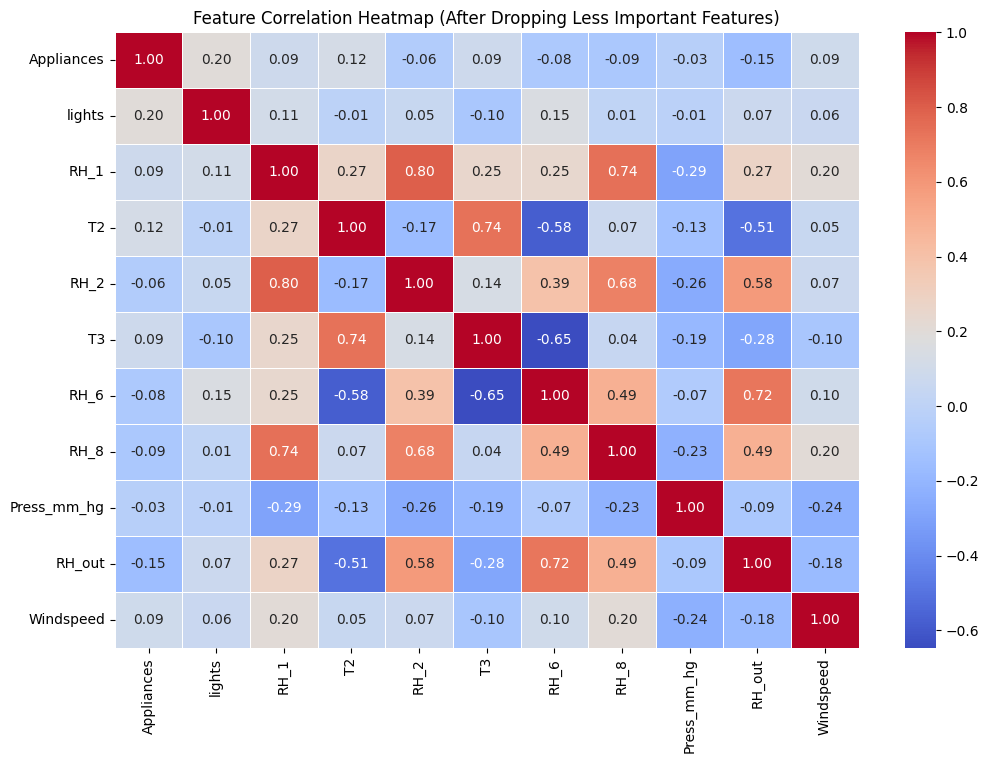

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

df_copied = data.copy()
if 'date' in df_copied.columns:
    df_copied.drop(columns=['date'], inplace=True)

correlation_matrix = df_copied.corr()

corr_with_target = correlation_matrix["Appliances"].abs().sort_values(ascending=False)


highly_corr_features = corr_with_target[corr_with_target > 0.03].index.tolist()
weak_corr_features = corr_with_target[corr_with_target < 0.03].index.tolist()

df_copied.drop(columns=weak_corr_features, inplace=True)
print(f"Removed weak correlation features: {weak_corr_features}")

correlation_matrix = df_copied.corr()


corr_threshold = 0.8
high_corr_pairs = set()

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > corr_threshold:
            feature_1 = correlation_matrix.columns[i]
            feature_2 = correlation_matrix.columns[j]

            if corr_with_target[feature_1] > corr_with_target[feature_2]:
                high_corr_pairs.add(feature_2)
            else:
                high_corr_pairs.add(feature_1)

df_copied.drop(columns=high_corr_pairs, inplace=True)
print(f"Dropped highly correlated features: {high_corr_pairs}")

print(f"Final selected features: {list(df_copied.columns)}")

plt.figure(figsize=(12, 8))
sns.heatmap(df_copied.corr(), annot=True, cmap="coolwarm", fmt='.2f' , linewidths=0.5)
plt.title("Feature Correlation Heatmap (After Dropping Less Important Features)")
plt.show()

In [51]:
df_copied.shape

(19735, 11)

In [52]:
df_copied.insert(0, 'date', data['date'])
df_copied.head(2)

,date,Appliances,lights,RH_1,T2,RH_2,T3,RH_6,RH_8,Press_mm_hg,RH_out,Windspeed
0,2016-01-11 17:00:00,60,30,47.596667,19.2,44.7900,19.79,84.256667,48.900000,733.5,92.0,7.000000
1,2016-01-11 17:10:00,60,30,46.693333,19.2,44.7225,19.79,84.063333,48.863333,733.6,92.0,6.666667


In [21]:
save_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/df_copied_LSTM_10.csv'
df_copied.to_csv(save_path, index=False)

-----

In [53]:
# The whole energydata_reviewed 26(1-trarget + 25) + 7 time based-features
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

original_data = data.copy()

data = original_data.set_index('date')
data.index = pd.to_datetime(data.index)

data['Appliances_lag_1'] = data['Appliances'].shift(1)
data['Appliances_lag_2'] = data['Appliances'].shift(2)
data['lights_lag'] = data['lights'].shift(2)

data['Appliances_rolling_mean'] = data['Appliances'].rolling(window=3).mean()
data['Appliances_rolling_std'] = data['Appliances'].rolling(window=6).std()
data['T2_rolling_mean'] = data['T2'].rolling(window=6).mean()

data['hour'] = data.index.hour
data['hour_sin'] = np.sin(2 * np.pi * data['hour'] / 24)

data.dropna(inplace=True)
data.drop(columns=['hour'], inplace=True)

scaler = MinMaxScaler()

normalized_features = scaler.fit_transform(data.drop(columns=['Appliances']))
normalized_target = scaler.fit_transform(data[['Appliances']])

normalized_features_df = pd.DataFrame(normalized_features, columns=data.drop(columns=['Appliances']).columns, index=data.index)
normalized_target_df = pd.DataFrame(normalized_target, columns=['Appliances'], index=data.index)

def create_sequences_with_lag(features, target, time_steps):
    X, y = [], []
    for i in range(len(features) - time_steps):
        X.append(features[i:i + time_steps].values)
        y.append(target[i + time_steps])
    return np.array(X), np.array(y)

time_steps = 30
X, y = create_sequences_with_lag(normalized_features_df, normalized_target_df['Appliances'], time_steps)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

{
    "Shape of X_train": X_train.shape,
    "Shape of y_train": y_train.shape,
    "Shape of X_test": X_test.shape,
    "Shape of y_test": y_test.shape,
    "Time steps": time_steps,
}

<ipython-input-53-d814db11dc37>:38: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y.append(target[i + time_steps])


,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,Windspeed,Visibility,Tdewpoint,Appliances_lag_1,Appliances_lag_2,lights_lag,Appliances_rolling_mean,Appliances_rolling_std,T2_rolling_mean,hour_sin
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:50:00,0.571429,0.32735,0.522980,0.225345,0.675883,0.215188,0.755569,0.341441,0.771233,0.172320,...,0.380952,0.658974,0.515837,0.046729,0.037383,0.571429,0.044,0.012588,0.227477,0.017037
2016-01-11 18:00:00,0.714286,0.32735,0.515824,0.225345,0.675883,0.215188,0.754012,0.341441,0.773794,0.169135,...,0.357143,0.600000,0.511312,0.037383,0.046729,0.571429,0.048,0.012588,0.227477,0.000000


In [55]:
normalized_features_df.columns

Index(['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5',
       'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out',
       'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint',
       'Appliances_lag_1', 'Appliances_lag_2', 'lights_lag',
       'Appliances_rolling_mean', 'Appliances_rolling_std', 'T2_rolling_mean',
       'hour_sin'],
      dtype='object')

In [23]:
data.columns

Index(['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4',
       'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9',
       'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility',
       'Tdewpoint', 'Appliances_lag_1', 'Appliances_lag_2', 'lights_lag',
       'Appliances_rolling_mean', 'Appliances_rolling_std', 'T2_rolling_mean',
       'hour_sin'],
      dtype='object')

The preprocessing has been successfully updated:

Features:

Lag features added (Appliances_lag_1, Appliances_lag_2).
Rolling statistics included (Appliances_rolling_mean, Appliances_rolling_std).
Total features increased to 31.
Time Steps: Increased to 30 for better historical context.

Training and Testing Data:
* X_train : Shape (15762, 30, 31).
* y_train : Shape (15762,).
* X_test : Shape (3941, 30, 31).
* y_test​ : Shape (3941,).

This dataset is now ready for modeling. Next, we can define and train the LSTM model.

In [24]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

def root_mean_squared_error(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_pred - y_true)))

model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss=root_mean_squared_error, metrics=['mse'])

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - loss: 0.0896 - mse: 0.0106 - val_loss: 0.0473 - val_mse: 0.0057
Epoch 2/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.0753 - mse: 0.0073 - val_loss: 0.0433 - val_mse: 0.0046
Epoch 3/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 0.0688 - mse: 0.0060 - val_loss: 0.0406 - val_mse: 0.0037
Epoch 4/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.0630 - mse: 0.0051 - val_loss: 0.0385 - val_mse: 0.0035
Epoch 5/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - loss: 0.0606 - mse: 0.0049 - val_loss: 0.0376 - val_mse: 0.0033
Epoch 6/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - loss: 0.0576 - mse: 0.0044 - val_loss: 0.0371 - val_mse: 0.0032
Epoch 7/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 0.0578 - mse: 0.0044 - val_loss: 0.0379 - val_mse: 0.0035
Epoch 8/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - loss: 0.0568 - mse: 0.0043 - val_loss: 0.0370 - val_mse: 0.0033
Epoch 9/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/ste

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                        │ (None, 30, 50)              │          16,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 30, 50)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 50)                  │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,555 (431.86 KB)

 Trainable params: 36,851 (143.95 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 73,704 (287.91 KB)

124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
RMSE: 57.706534958356166
MSE: 3330.044176899982
MAE: 26.103403694617565
R² Score: 0.5932880130054328


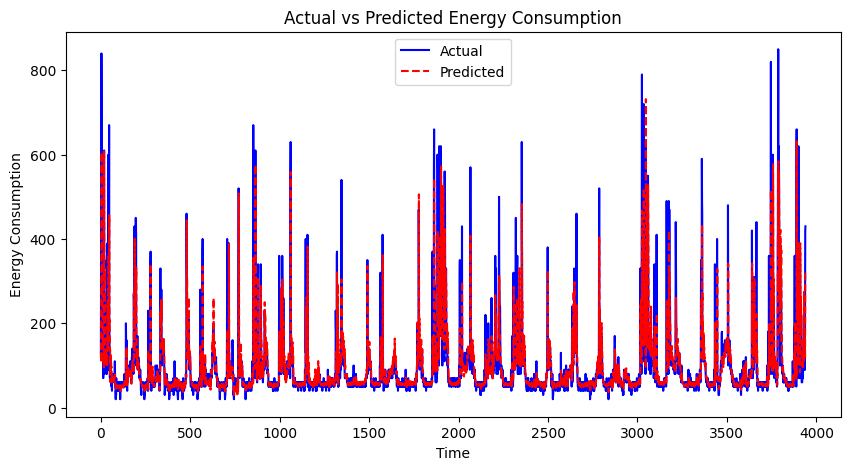

In [25]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

y_pred = scaler.inverse_transform(y_pred.reshape(-1, 1))
y_test = scaler.inverse_transform(y_test.reshape(-1, 1))

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

#metrics
print(f"RMSE: {rmse}")
print(f"MSE: {mse}")
print(f"MAE: {mae}")
print(f"R² Score: {r2}")

plt.figure(figsize=(10, 5))
plt.plot(y_test, label='Actual', color='blue')
plt.plot(y_pred, label='Predicted', color='red', linestyle='dashed')
plt.xlabel('Time')
plt.ylabel('Energy Consumption')
plt.title('Actual vs Predicted Energy Consumption')
plt.legend()
plt.show()

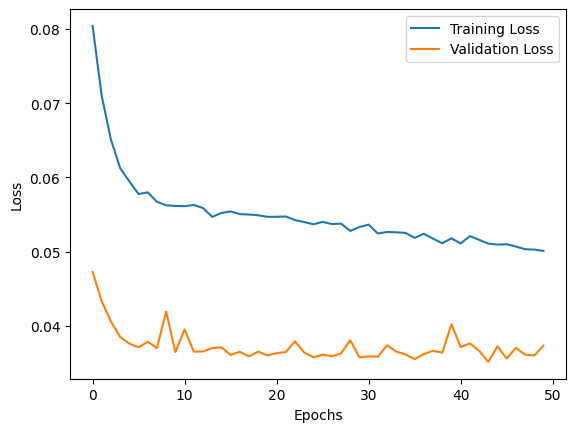

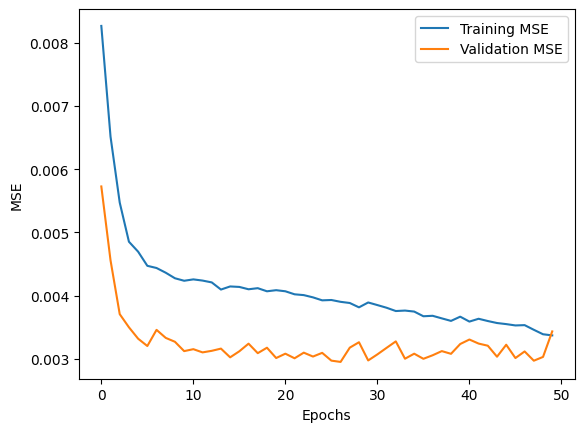

In [26]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.plot(history.history['mse'], label='Training MSE')
plt.plot(history.history['val_mse'], label='Validation MSE')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.legend()
plt.show()

In [27]:
model.save('model.keras', model)
print("Saved")

Saved


---
# LSTM with less features

In [74]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/df_copied_LSTM_10.csv'
df_copied = pd.read_csv(file_path)
df_copied.dtypes

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,0
date,object
Appliances,int64
lights,int64
RH_1,float64
T2,float64
RH_2,float64
T3,float64
RH_6,float64
RH_8,float64
Press_mm_hg,float64


In [75]:
import pandas as pd

df_copied['date'] = pd.to_datetime(df_copied['date'])

df_copied['hour'] = df_copied['date'].dt.hour
df_copied['hour_sin'] = np.sin(2 * np.pi * df_copied['hour'] / 24)

df_copied['Appliances_lag_1'] = df_copied['Appliances'].shift(1)
df_copied['Appliances_lag_2'] = df_copied['Appliances'].shift(2)
df_copied['lights_lag'] = df_copied['lights'].shift(2)

df_copied['Appliances_rolling_mean'] = df_copied['Appliances'].rolling(window=3).mean()
df_copied['Appliances_rolling_std'] = df_copied['Appliances'].rolling(window=6).std()
df_copied['T2_rolling_mean'] = df_copied['T2'].rolling(window=6).mean()

df_copied.dropna(inplace=True)
df_copied.drop(columns=['hour', 'date'], inplace=True)

scaler = MinMaxScaler()

normalized_features = scaler.fit_transform(df_copied.drop(columns=['Appliances']))
normalized_target = scaler.fit_transform(df_copied[['Appliances']])

normalized_features_df = pd.DataFrame(normalized_features, columns=df_copied.drop(columns=['Appliances']).columns, index=df_copied.index)
normalized_target_df = pd.DataFrame(normalized_target, columns=['Appliances'], index=df_copied.index)

def create_sequences_with_lag(features, target, time_steps):
    X, y = [], []
    for i in range(len(features) - time_steps):
        X.append(features[i:i + time_steps].values)
        y.append(target[i + time_steps])
    return np.array(X), np.array(y)

time_steps = 30
X, y = create_sequences_with_lag(normalized_features_df, normalized_target_df['Appliances'], time_steps)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

{
    "Shape of X_train": X_train.shape,
    "Shape of y_train": y_train.shape,
    "Shape of X_test": X_test.shape,
    "Shape of y_test": y_test.shape,
    "Time steps": time_steps,
}

{'Shape of X_train': (15760, 30, 17),
 'Shape of y_train': (15760,),
 'Shape of X_test': (3940, 30, 17),
 'Shape of y_test': (3940,),
 'Time steps': 30}

In [76]:
df_copied.columns

Index(['Appliances', 'lights', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_6', 'RH_8',
       'Press_mm_hg', 'RH_out', 'Windspeed', 'hour_sin', 'Appliances_lag_1',
       'Appliances_lag_2', 'lights_lag', 'Appliances_rolling_mean',
       'Appliances_rolling_std', 'T2_rolling_mean'],
      dtype='object')

In [77]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

def root_mean_squared_error(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_pred - y_true)))

model_2nd = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model_2nd.compile(optimizer='adam', loss=root_mean_squared_error)

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model_2nd.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

model_2nd.summary()

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


887/887 ━━━━━━━━━━━━━━━━━━━━ 29s 29ms/step - loss: 0.0675 - val_loss: 0.0316
Epoch 2/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 23s 25ms/step - loss: 0.0371 - val_loss: 0.0199
Epoch 3/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 25s 28ms/step - loss: 0.0266 - val_loss: 0.0126
Epoch 4/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - loss: 0.0227 - val_loss: 0.0088
Epoch 5/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - loss: 0.0157 - val_loss: 0.0071
Epoch 6/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 40s 26ms/step - loss: 0.0138 - val_loss: 0.0048
Epoch 7/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - loss: 0.0137 - val_loss: 0.0062
Epoch 8/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - loss: 0.0125 - val_loss: 0.0054
Epoch 9/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - loss: 0.0128 - val_loss: 0.0050
Epoch 10/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - loss: 0.0119 - val_loss: 0.0070
Epoch 11/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 25s 28ms/step - loss: 0.0111 - val_loss: 0.0065
Epoch 12/50
887/887 ━━━━━━━━━━━━━━━━━━━━ 

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 30, 50)              │          13,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 30, 50)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 50)                  │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,555 (396.70 KB)

 Trainable params: 33,851 (132.23 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 67,704 (264.47 KB)

493/493 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
TEST : MAE: 2.036303819859693, mse: 12.825219562329561, R²: 0.9984281341153499


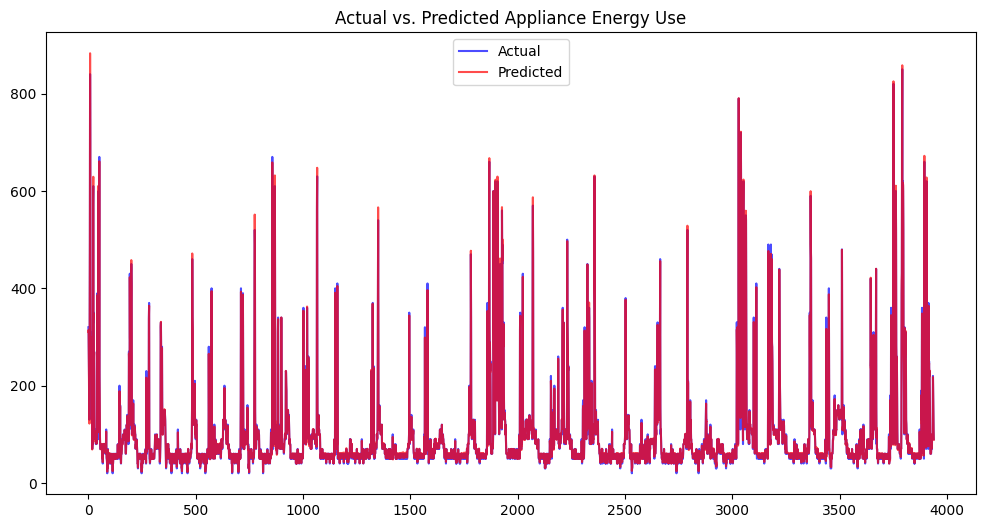

In [78]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

y_pred_train = model_2nd.predict(X_train)
y_pred_train = scaler.inverse_transform(y_pred_train)
y_train_original = scaler.inverse_transform(y_train.reshape(-1, 1))

y_pred_test = model_2nd.predict(X_test)
y_pred_test = scaler.inverse_transform(y_pred_test)
y_test_original = scaler.inverse_transform(y_test.reshape(-1, 1))

mae_train = mean_absolute_error(y_train_original, y_pred_train)
mae = mean_absolute_error(y_test_original, y_pred_test)

mse_train = mean_squared_error(y_train, y_pred_train)
mse = mean_squared_error(y_test_original, y_pred_test)

r2_train = r2_score(y_train, y_pred_train)
r2 = r2_score(y_test_original, y_pred_test)

print(f"TEST : MAE: {mae}, mse: {mse}, R²: {r2}")

plt.figure(figsize=(12, 6))
plt.plot(y_test_original, label='Actual', color='blue', alpha=0.7)
plt.plot(y_pred_test, label='Predicted', color='red', alpha=0.7)
plt.title('Actual vs. Predicted Appliance Energy Use')
plt.legend()
plt.show()

493/493 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


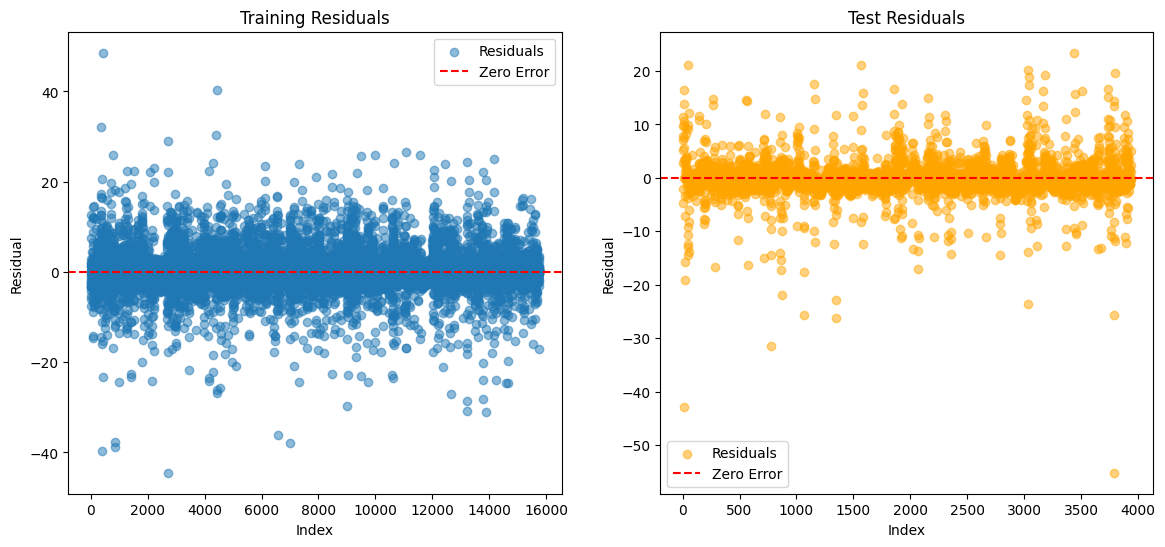

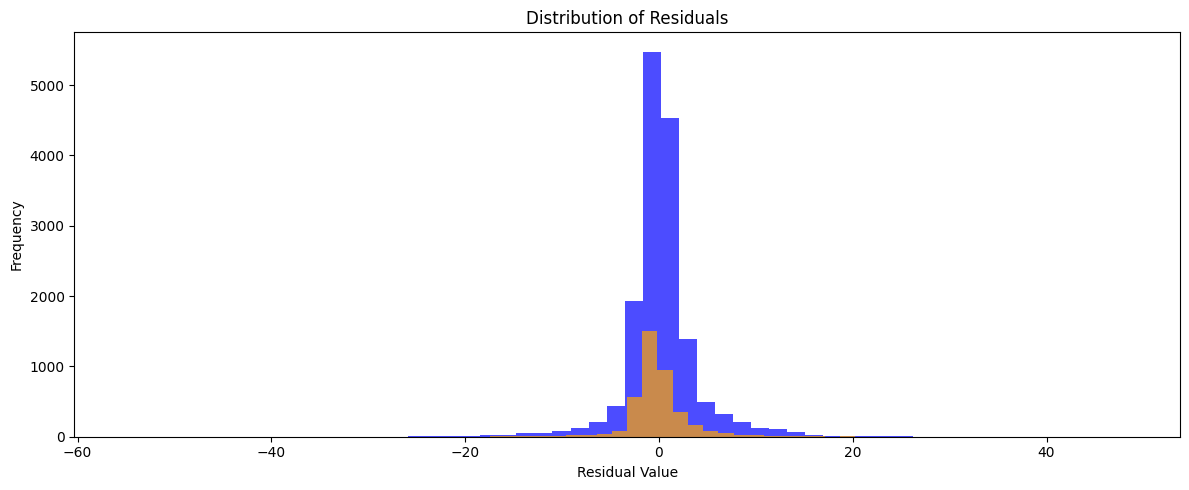

In [79]:
import matplotlib.pyplot as plt
import numpy as np

y_pred_train = model_2nd.predict(X_train)
y_pred_train = scaler.inverse_transform(y_pred_train)
y_train_original = scaler.inverse_transform(y_train.reshape(-1, 1))

y_pred_test = model_2nd.predict(X_test)
y_pred_test = scaler.inverse_transform(y_pred_test)
y_test_original = scaler.inverse_transform(y_test.reshape(-1, 1))

train_residuals = y_train_original - y_pred_train
test_residuals = y_test_original - y_pred_test

plt.figure(figsize=(14, 6))

#Training residuals
plt.subplot(1, 2, 1)
plt.scatter(range(len(train_residuals)), train_residuals, alpha=0.5, label="Residuals")
plt.axhline(0, color='red', linestyle='--', label="Zero Error")
plt.title("Training Residuals")
plt.xlabel("Index")
plt.ylabel("Residual")
plt.legend()

#Test residuals
plt.subplot(1, 2, 2)
plt.scatter(range(len(test_residuals)), test_residuals, alpha=0.5, color='orange', label="Residuals")
plt.axhline(0, color='red', linestyle='--', label="Zero Error")
plt.title("Test Residuals")
plt.xlabel("Index")
plt.ylabel("Residual")
plt.legend()

#Histograms of residuals
plt.figure(figsize=(12, 5))
plt.hist(train_residuals, bins=50, alpha=0.7, label='Training Residuals', color='blue')
plt.hist(test_residuals, bins=50, alpha=0.7, label='Test Residuals', color='orange')
plt.title("Distribution of Residuals")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


The histogram suggests that most residuals are close to zero, indicating that the model's predictions are mostly accurate.
The residuals appear to be normally distributed, which is desirable for not overfitting or missing patterns.
Some extreme residuals (outliers) exist, but they are very less compared with the remainder data samples. The variance of residuals remains relatively stable, suggesting the model generalizes well.


In [36]:
model_2nd.save('model2.keras', model_2nd)
print("Saved")

Saved


## GRU (FASTER THAN LSTM, We will try with the reduced dataset)

In [59]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

def create_sequences(data, seq_length):
    sequences = []
    for i in range(len(data) - seq_length):
        seq = data[i:i+seq_length]
        sequences.append(seq)
    return np.array(sequences)

def root_mean_squared_error(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_pred - y_true)))

seq_length = 24
X = create_sequences(normalized_features_df, seq_length)

y = normalized_target_df['Appliances'][seq_length:]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)


model3 = Sequential()
model3.add(GRU(units=50, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
model3.add(Dropout(0.2))
model3.add(GRU(units=10, activation='relu'))
model3.add(Dropout(0.3))
model3.add(Dense(units=1))

model3.compile(optimizer='adam', loss=root_mean_squared_error)

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = model3.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

loss = model3.evaluate(X_test, y_test)
print(f"Test Loss: {loss}")

predictions = model3.predict(X_test)

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - loss: 0.0866 - val_loss: 0.0543
Epoch 2/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - loss: 0.0778 - val_loss: 0.0503
Epoch 3/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - loss: 0.0735 - val_loss: 0.0519
Epoch 4/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - loss: 0.0721 - val_loss: 0.0454
Epoch 5/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - loss: 0.0673 - val_loss: 0.0476
Epoch 6/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - loss: 0.0654 - val_loss: 0.0477
Epoch 7/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - loss: 0.0630 - val_loss: 0.0453
Epoch 8/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0665 - val_loss: 0.0459
Epoch 9/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - loss: 0.0632 - val_loss: 0.0437
Epoch 10/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0656 - val_loss: 0.0465
Epoch 11/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - loss: 0.0641 - val_loss: 0.0428
Epoch 12/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 

124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
493/493 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
TRAIN : R²: 0.6096266248637732
TEST MAE: 25.279336520949336, mse: 3461.419206642204, R²: 0.5771820297547792


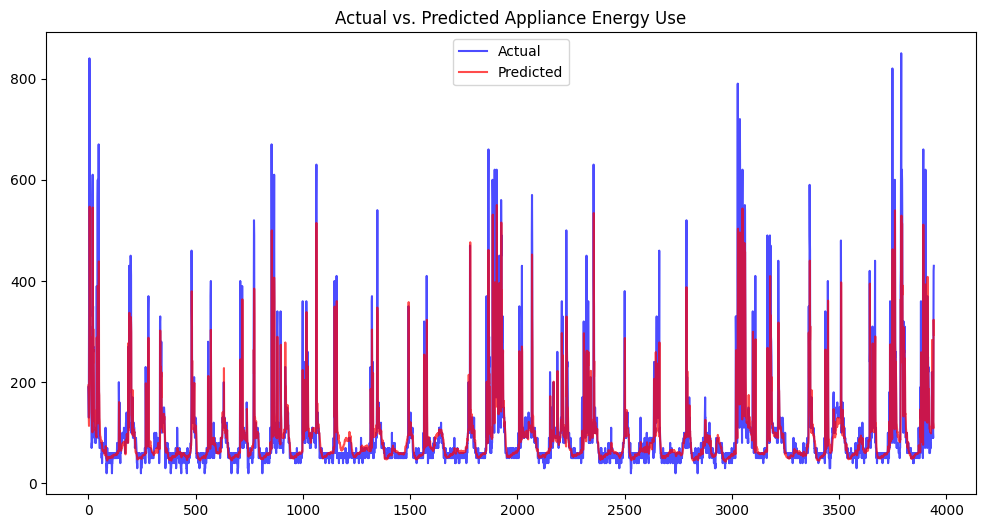

In [61]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

predictions = model3.predict(X_test)

predictions = scaler.inverse_transform(predictions)
y_test_original = scaler.inverse_transform(y_test.values.reshape(-1, 1))

mae = mean_absolute_error(y_test_original, predictions)
mse = mean_squared_error(y_test_original, predictions)
r2_train = r2_score(y_train, model3.predict(X_train))
r2 = r2_score(y_test_original, predictions)

print(f"TRAIN : R²: {r2_train}")
print(f"TEST MAE: {mae}, mse: {mse}, R²: {r2}")

plt.figure(figsize=(12, 6))
plt.plot(y_test_original, label='Actual', color='blue',alpha=0.7)
plt.plot(predictions, label='Predicted', color='red',alpha=0.7)
plt.title('Actual vs. Predicted Appliance Energy Use')
plt.legend()
plt.show()

493/493 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


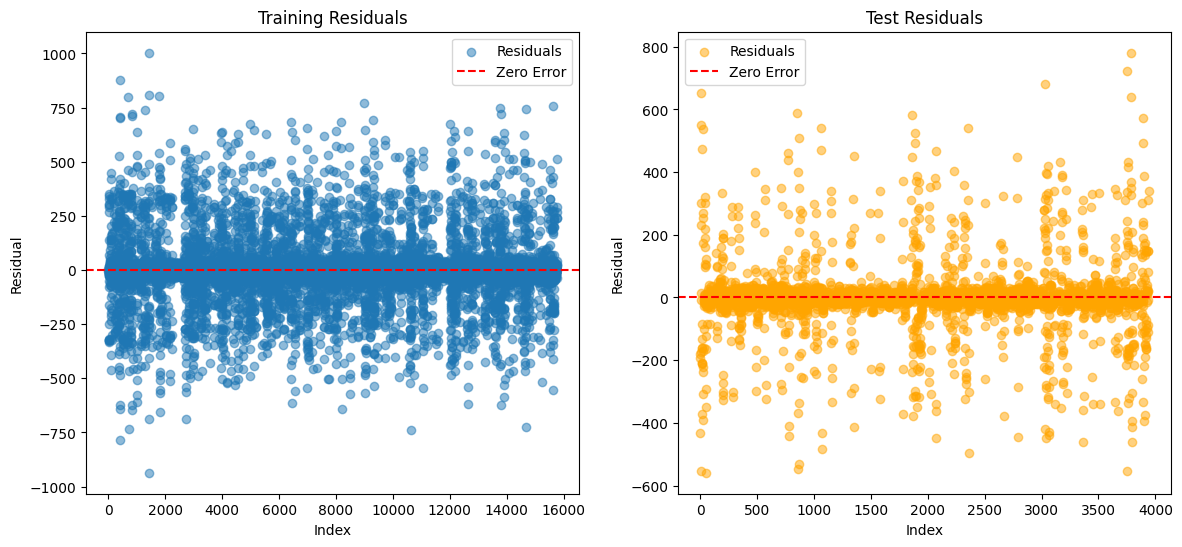

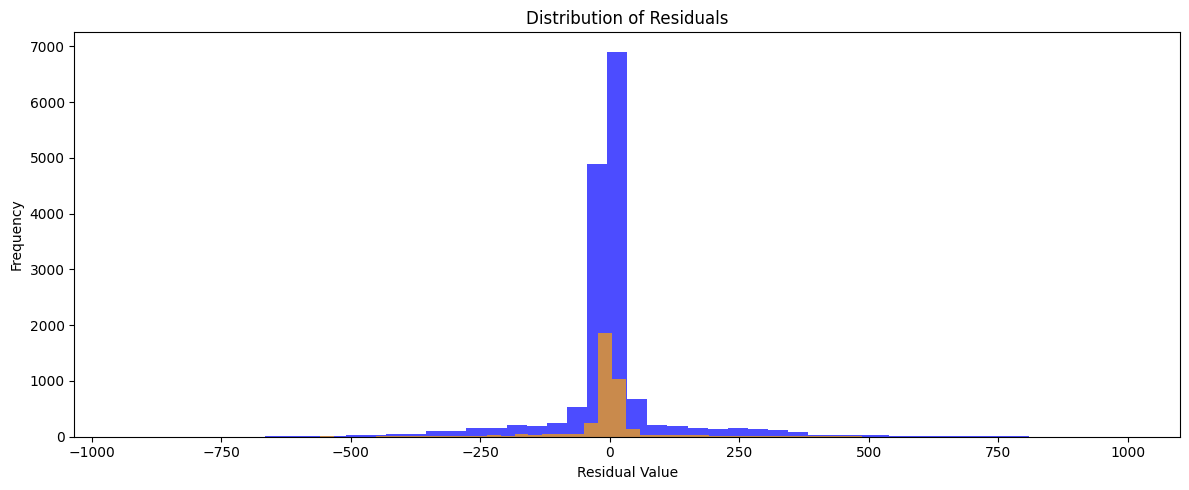

In [40]:
import matplotlib.pyplot as plt
import numpy as np

y_pred_train = model_2nd.predict(X_train)
y_pred_train = scaler.inverse_transform(y_pred_train)
y_train_original = scaler.inverse_transform(y_train.values.reshape(-1, 1))

y_pred_test = model_2nd.predict(X_test)
y_pred_test = scaler.inverse_transform(y_pred_test)
y_test_original = scaler.inverse_transform(y_test.values.reshape(-1, 1))

train_residuals = y_train_original - y_pred_train
test_residuals = y_test_original - y_pred_test

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.scatter(range(len(train_residuals)), train_residuals, alpha=0.5, label="Residuals")
plt.axhline(0, color='red', linestyle='--', label="Zero Error")
plt.title("Training Residuals")
plt.xlabel("Index")
plt.ylabel("Residual")
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(range(len(test_residuals)), test_residuals, alpha=0.5, color='orange', label="Residuals")
plt.axhline(0, color='red', linestyle='--', label="Zero Error")
plt.title("Test Residuals")
plt.xlabel("Index")
plt.ylabel("Residual")
plt.legend()

plt.figure(figsize=(12, 5))
plt.hist(train_residuals, bins=50, alpha=0.7, label='Training Residuals', color='blue')
plt.hist(test_residuals, bins=50, alpha=0.7, label='Test Residuals', color='orange')
plt.title("Distribution of Residuals")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

--------------------

In [63]:
df = pd.read_csv('/content/drive/MyDrive/Machine_Learning/Final_Project/energydata_reviewed.csv')
df.head(2)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.7900,19.79,44.73,19.0,...,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.7225,19.79,44.79,19.0,...,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2


** Autoencoders (Advanced & Smart)**

Autoencoders learn a compressed version of the data while preserving time-series patterns.Works like PCA but keeps sequential integrity, which is crucial for LSTMs.

Pros: Learns hidden relationships, reduces feature count.

Cons: More complex to implement

## Feature Engineering - Dropping the low correlated features with "Appliances" and the high correlated features with other "indepedent" features and keeping the high correlated ones with the "Appliances"

Removed weak correlation features: ['T7', 'T5', 'RH_4', 'Tdewpoint', 'T9', 'RH_5', 'Visibility']
Dropped highly correlated features: {'T_out', 'T4', 'RH_3', 'RH_7', 'RH_2', 'T8', 'T6', 'RH_6', 'T3', 'RH_1', 'RH_9', 'T1'}
Final selected features: ['Appliances', 'lights', 'T2', 'RH_8', 'Press_mm_hg', 'RH_out', 'Windspeed']


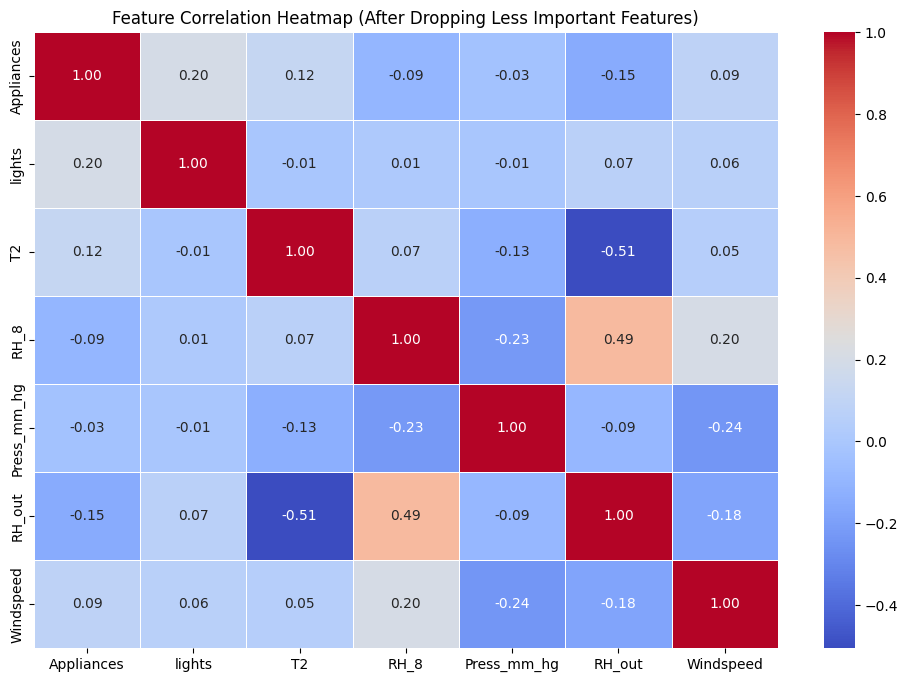

In [64]:
df_copied = df.copy()
if 'date' in df_copied.columns:
    df_copied.drop(columns=['date'], inplace=True)


correlation_matrix = df_copied.corr()

corr_with_target = correlation_matrix["Appliances"].abs().sort_values(ascending=False)

highly_corr_features = corr_with_target[corr_with_target > 0.03].index.tolist()   # Important features
weak_corr_features = corr_with_target[corr_with_target < 0.03].index.tolist()  # Features with very low impact

df_copied.drop(columns=weak_corr_features, inplace=True)
print(f"Removed weak correlation features: {weak_corr_features}")

correlation_matrix = df_copied.corr()

corr_threshold = 0.7
high_corr_pairs = set()

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > corr_threshold:
            feature_1 = correlation_matrix.columns[i]
            feature_2 = correlation_matrix.columns[j]


            if corr_with_target[feature_1] > corr_with_target[feature_2]:
                high_corr_pairs.add(feature_2)
            else:
                high_corr_pairs.add(feature_1)


df_copied.drop(columns=high_corr_pairs, inplace=True)
print(f"Dropped highly correlated features: {high_corr_pairs}")

print(f"Final selected features: {list(df_copied.columns)}")

plt.figure(figsize=(12, 8))
sns.heatmap(df_copied.corr(), annot=True, cmap="coolwarm", fmt='.2f' , linewidths=0.5)
plt.title("Feature Correlation Heatmap (After Dropping Less Important Features)")
plt.show()

In [43]:
df_copied = df[['date'] + [col for col in df_copied.columns if col != 'date']]
df_high_corr = df_copied.copy()
save_path_high_corr = '/content/drive/MyDrive/Machine_Learning/Final_Project/df_high_corr.csv'
df_high_corr.to_csv(save_path_high_corr, index=False)

In [67]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/df_high_corr.csv'
df_high_corr = pd.read_csv(file_path)
df_high_corr.head(2)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,date,Appliances,lights,T2,RH_8,Press_mm_hg,RH_out,Windspeed
0,2016-01-11 17:00:00,60,30,19.2,48.900000,733.5,92.0,7.000000
1,2016-01-11 17:10:00,60,30,19.2,48.863333,733.6,92.0,6.666667


In [68]:
df_high_corr.dtypes

,0
date,object
Appliances,int64
lights,int64
T2,float64
RH_8,float64
Press_mm_hg,float64
RH_out,float64
Windspeed,float64


In [4]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

target_col = 'Appliances'

df_high_corr['date'] = pd.to_datetime(df_high_corr['date'])
df_high_corr.set_index('date', inplace=True)

feature_names = df_high_corr.drop(columns=['Appliances']).columns

X = df_high_corr.drop(columns=['Appliances']).values
y = df_high_corr['Appliances'].values

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1))


X_scaled_df = pd.DataFrame(X_scaled, columns=feature_names, index=df_high_corr.index)
y_scaled_df = pd.DataFrame(y_scaled, columns=[target_col], index=df_high_corr.index)

normalized_df = pd.concat([X_scaled_df, y_scaled_df], axis=1)
print(normalized_df.head(2))

save_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/normalized_df.csv'
normalized_df.to_csv(save_path, index=True)

                       lights        T2      RH_8  Press_mm_hg    RH_out  \
date                                                                       
2016-01-11 17:00:00  0.428571  0.225345  0.661412     0.097674  0.894737   
2016-01-11 17:10:00  0.428571  0.225345  0.660155     0.100000  0.894737   

                     Windspeed  Appliances  
date                                        
2016-01-11 17:00:00    0.50000    0.046729  
2016-01-11 17:10:00    0.47619    0.046729  


 The lights are interpreted as if they are present or no. Because of this we can use the rolling average of them instead of transforming it as binary or something like that. As for the others  

In [69]:
df_processed = normalized_df.copy()

In [70]:
normalized_df.shape

(19735, 7)

## Add time-based features

# Lag Features (Using past values of the most correlated features with Appliances)
lag_features = ['Appliances', 'lights', 'T2', 'RH_out']
for col in lag_features:
    df_processed[f"{col}_lag_1"] = df_processed[col].shift(1)
    df_processed[f"{col}_lag_3"] = df_processed[col].shift(3)

# Rolling Averages (Smoothing short-term fluctuations for all the features)
rolling_features = ['Appliances', 'T2', 'RH_8', 'Press_mm_hg', 'RH_out', 'Windspeed', 'lights']
for col in rolling_features:
    df_processed[f"{col}_rolling_3"] = df_processed[col].rolling(window=3).mean()
    df_processed[f"{col}_rolling_6"] = df_processed[col].rolling(window=6).mean()

# Time-of-Day Features (Capturing daily and seasonal patterns)
df_processed['hour'] = df_processed.index.hour
df_processed['day_of_week'] = df_processed.index.dayofweek
df_processed['month'] = df_processed.index.month

# Convert time-based features into cyclical features (sin & cos transformation)
df_processed['hour_sin'] = np.sin(2 * np.pi * df_processed['hour'] / 24)
df_processed['hour_cos'] = np.cos(2 * np.pi * df_processed['hour'] / 24)
df_processed['day_of_week_sin'] = np.sin(2 * np.pi * df_processed['day_of_week'] / 7)
df_processed['day_of_week_cos'] = np.cos(2 * np.pi * df_processed['day_of_week'] / 7)

# Dropping the NaN values
max_na_cutoff = max(3, 6)  # The longest rolling window or lag (6)
df_processed = df_processed.iloc[max_na_cutoff:]  # Drop only first few NaN rows

# Drop raw time-based categorical columns after transformation
df_processed.drop(columns=['hour', 'day_of_week', 'month'], inplace=True)
df_processed.head(2)

In [ ]:
save_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/df_GRU.csv'
df_processed.to_csv(save_path, index=True)

In [71]:
df_processed.head(2)

,lights,T2,RH_8,Press_mm_hg,RH_out,Windspeed,Appliances
date,,,,,,,
2016-01-11 17:00:00,0.428571,0.225345,0.661412,0.097674,0.894737,0.50000,0.046729
2016-01-11 17:10:00,0.428571,0.225345,0.660155,0.100000,0.894737,0.47619,0.046729


In [72]:
df_processed['hour'] = df_processed.index.hour
df_processed['hour_sin'] = np.sin(2 * np.pi * df_processed['hour'] / 24)
df_processed.drop(columns=['hour'], inplace=True)

df_processed['appliances_rolling_avg3'] = df_processed['Appliances'].rolling(window=3).mean()
df_processed['appliances_rolling_avg6'] = df_processed['Appliances'].rolling(window=6).mean()

df_processed['appliances_lag_1'] = df_processed['Appliances'].shift(1)
df_processed['appliances_lag_2'] = df_processed['Appliances'].shift(2)

df_processed['lights_lag'] = df_processed['lights'].shift(2)
df_processed['T2_rolling_mean'] = df_processed['T2'].rolling(window=6).mean()

df_processed.dropna(inplace=True)

df_processed.head(2)

,lights,T2,RH_8,Press_mm_hg,RH_out,Windspeed,Appliances,hour_sin,appliances_rolling_avg3,appliances_rolling_avg6,appliances_lag_1,appliances_lag_2,lights_lag,T2_rolling_mean
date,,,,,,,,,,,,,,
2016-01-11 17:50:00,0.571429,0.225345,0.650788,0.109302,0.894737,0.380952,0.037383,-0.965926,0.040498,0.042056,0.046729,0.037383,0.571429,0.225345
2016-01-11 18:00:00,0.714286,0.225345,0.650788,0.111628,0.894737,0.357143,0.046729,-1.000000,0.043614,0.042056,0.037383,0.046729,0.571429,0.225345


In [73]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split


def create_sequences(data, seq_length):
    sequences = []
    for i in range(len(data) - seq_length):
        seq = data[i:i+seq_length]
        sequences.append(seq)
    return np.array(sequences)

def root_mean_squared_error(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_pred - y_true)))

seq_length = 24
X = create_sequences(df_processed, seq_length)

y = df_processed['Appliances'][seq_length:]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)


model4 = Sequential()
model4.add(GRU(units=50, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
model4.add(Dropout(0.2))
model4.add(GRU(units=20, activation='relu'))
model4.add(Dropout(0.3))
model4.add(Dense(units=1))

model4.compile(optimizer='adam', loss=root_mean_squared_error)

# 4. Train the model
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = model4.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

# 5. Evaluate the model
loss = model4.evaluate(X_test, y_test)
print(f"Test Loss: {loss}")

# Make predictions
predictions = model4.predict(X_test)

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


493/493 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - loss: 0.0881 - val_loss: 0.0502
Epoch 2/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - loss: 0.0715 - val_loss: 0.0449
Epoch 3/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - loss: 0.0626 - val_loss: 0.0424
Epoch 4/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 22s 34ms/step - loss: 0.0642 - val_loss: 0.0444
Epoch 5/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - loss: 0.0607 - val_loss: 0.0421
Epoch 6/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - loss: 0.0618 - val_loss: 0.0414
Epoch 7/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - loss: 0.0604 - val_loss: 0.0417
Epoch 8/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - loss: 0.0605 - val_loss: 0.0438
Epoch 9/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - loss: 0.0595 - val_loss: 0.0420
Epoch 10/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - loss: 0.0601 - val_loss: 0.0416
Epoch 11/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - loss: 0.0613 - val_loss: 0.0435
Epoch 12/50
493/493 ━━━━━━━━━━━━━━━━━━━━ 

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model4.predict(X_test)

y_pred_original = scaler_y.inverse_transform(y_pred)
y_test_original = scaler_y.inverse_transform(y_test.values.reshape(-1, 1))

#Μetrics
mae = mean_absolute_error(y_test_original, y_pred_original)
rmse = np.sqrt(mean_squared_error(y_test_original, y_pred_original))
r2 = r2_score(y_test_original, y_pred_original)

print(f"MAE: {mae}, RMSE: {rmse}, R²: {r2}")

124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
MAE: 24.207742611688143, RMSE: 57.37534684881417, R²: 0.5978853592052458


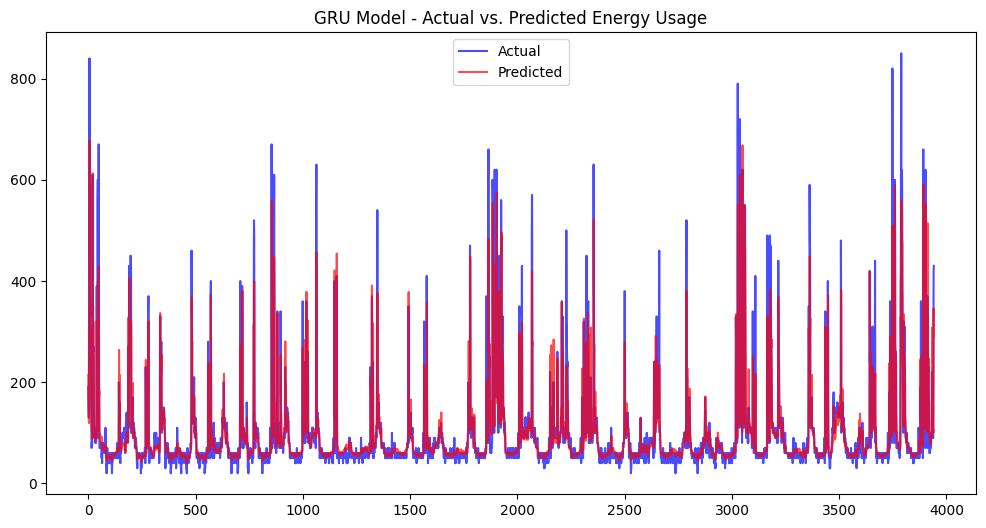

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(y_test_original, label="Actual",color='blue', alpha=0.7)
plt.plot(y_pred_original, label="Predicted", color='red',alpha=0.7)
plt.legend()
plt.title("GRU Model - Actual vs. Predicted Energy Usage")
plt.show()